# Solar filament segmentation with D-FINE-seg: the whole pipeline

This notebook runs the submitted solution end to end:

1. data: H-alpha observations and their per-annotator filament masks
2. dataset preparation (one sample per annotator view, split by date)
3. training (D-FINE-seg-S, semantic segmentation at native 2048 x 2048; skipped by default, the trained weights ship in `weights/`)
4. inference on one image, step by step: probability map -> threshold -> closing -> components -> confidence filter
5. validation metrics from the competition rubric, next to inter-annotator agreement
6. test predictions -> `submission.csv`, checked against the file submitted to Kaggle
7. end-to-end latency

Requirements: `pip install -r requirements.txt`, and the competition data unzipped to `data/MAGFiLO_1.0_Kaggle_2026` (or set `FILAMENT_DATA`).

In [1]:
import os, sys, time, json, subprocess
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
from loguru import logger

logger.remove()  # keep D-FINE-seg info logs out of the outputs
logger.add(sys.stderr, level="WARNING")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from filaments.data import load_views, split_dates, group_by_observation, prepare_sem_dataset
from filaments.inference import FilamentSegmenter, PostProcess, instances, write_submission
from filaments.metrics import evaluate, inter_annotator
from filaments import viz

DATA = Path(os.environ.get("FILAMENT_DATA", ROOT / "data/MAGFiLO_1.0_Kaggle_2026"))
WEIGHTS = ROOT / "weights/sem_s_2048.pt"
RUN_TRAINING = False  # ~3 h on a 16 GB GPU; the trained weights are in weights/
print("data:", os.path.relpath(DATA, ROOT), "| GPU:", torch.cuda.get_device_name() if torch.cuda.is_available() else "none")

data: data/MAGFiLO_1.0_Kaggle_2026 | GPU: NVIDIA GeForce RTX 5070 Ti


## 1. Data

707 training observations carry 1154 annotator views (1-3 independent annotators per observation) with 8199 filaments in total; the test set has 180 observations. Filaments are small and thin: the median filament covers 0.03% of the frame and many are ribbons only 5-15 px wide at 2048 x 2048, which is why the model runs at native resolution.

Annotators disagree a lot. Below: one observation, drawn by two annotators.

707 observations, 1154 annotator views, 8199 filaments


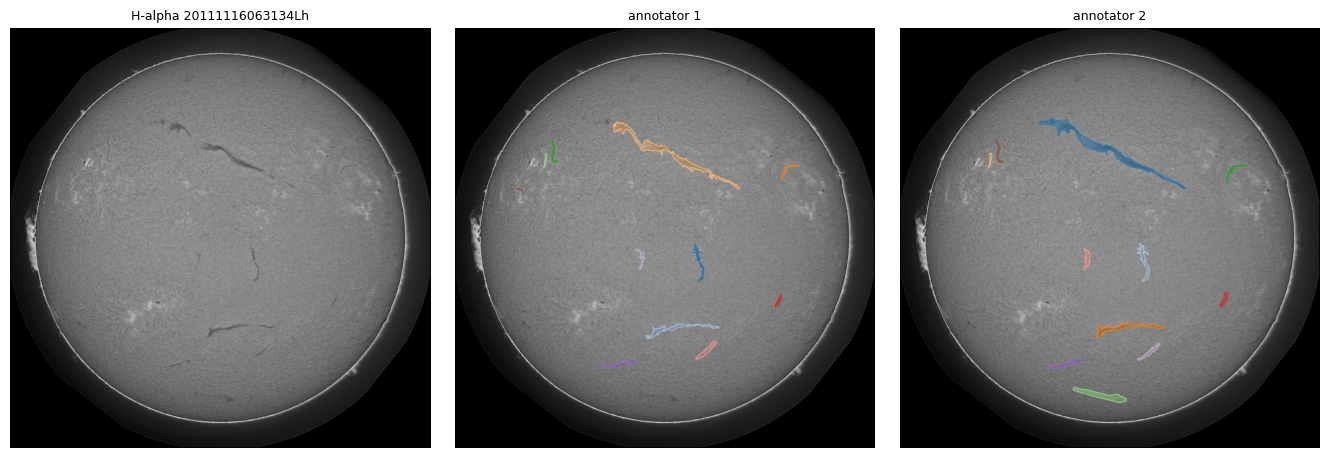

In [2]:
views = load_views(DATA)
gt_all = group_by_observation(views)
n_f = sum(len(v.rles) for v in views)
print(f"{len(gt_all)} observations, {len(views)} annotator views, {n_f} filaments")

stem = next(s for s, v in gt_all.items() if len(v) >= 2 and min(map(len, v)) >= 6)
img = cv2.imread(str(DATA / "train/train_images" / f"{stem}.jpeg"))
viz.show_row([
    ("H-alpha " + stem, cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
    ("annotator 1", viz.overlay(img, gt_all[stem][0])),
    ("annotator 2", viz.overlay(img, gt_all[stem][1])),
], size=4.5);

## 2. Dataset preparation

Every annotator view becomes its own training sample (the shared JPEG + that annotator's mask). Training on consensus masks (pixels all annotators agree on) or on the union of views both scored worse on validation (0.421 and 0.408 vs 0.429 PQ): the test views have individual annotators' styles, so the model should learn those.

The split holds out 20% of observation dates, so all views of an observation, and all frames of the same day, land in the same split: 906 train views / 248 validation views (144 observations).

In [3]:
prepare_sem_dataset(DATA, ROOT / "data/dataset_sem")
val_dates = split_dates([v.stem for v in views])
gt_val = {s: v for s, v in gt_all.items() if s[:8] in val_dates}
print("validation observations:", len(gt_val), "| views:", sum(map(len, gt_val.values())))

train views 906, val views 248 (144 observations)
validation observations: 144 | views: 248


## 3. Training

[D-FINE-seg](https://github.com/ArgoHA/D-FINE-seg) (`pip install dfine-seg`) semantic segmentation head (`task: sem_seg`), size S (~8M parameters), initialised from COCO instance-segmentation weights (downloaded automatically). Full 2048 x 2048 frames, batch 2, 60 epochs, flips + 90-degree rotations (the Sun has no preferred orientation), EMA, bf16 AMP. All settings are in `configs/config.yaml`.

Resolution was the biggest lever we found: the same model at 1280 x 1280 scored 0.360 PQ vs 0.417 at 2048 (argmax post-processing), because masks are predicted at 1/4 of the input resolution and filaments are only a few pixels wide.

In [4]:
if RUN_TRAINING:
    env = {**os.environ, "DFINE_SEG_CONFIG_DIR": str(ROOT / "configs")}
    subprocess.run(["dfine", "train"], check=True, env=env, cwd=ROOT)
    # the best checkpoint lands in output/models/sem_s_2048_<date>/model.pt
    WEIGHTS = sorted((ROOT / "output/models").glob("sem_s_2048_*/model.pt"))[-1]
print("weights:", os.path.relpath(WEIGHTS, ROOT))

weights: weights/sem_s_2048.pt


## 4. Inference, step by step

1. the network returns p(filament) for every pixel (one forward pass at 2048 x 2048);
2. threshold at 0.4;
3. morphological closing (disk, radius 4 px) reconnects pieces of the same filament;
4. 8-connected components are the filament instances (at least 200 px);
5. each component is scored by its mean probability and kept if >= 0.90. Panoptic Quality charges a false positive twice as much as a miss, so uncertain blobs are dropped.

All thresholds were tuned on the validation split; the confidence cut was confirmed with split-half cross-fitting (tune on half of the observations, score on the other half).

15 components >= 200 px, 9 kept with mean p >= 0.9


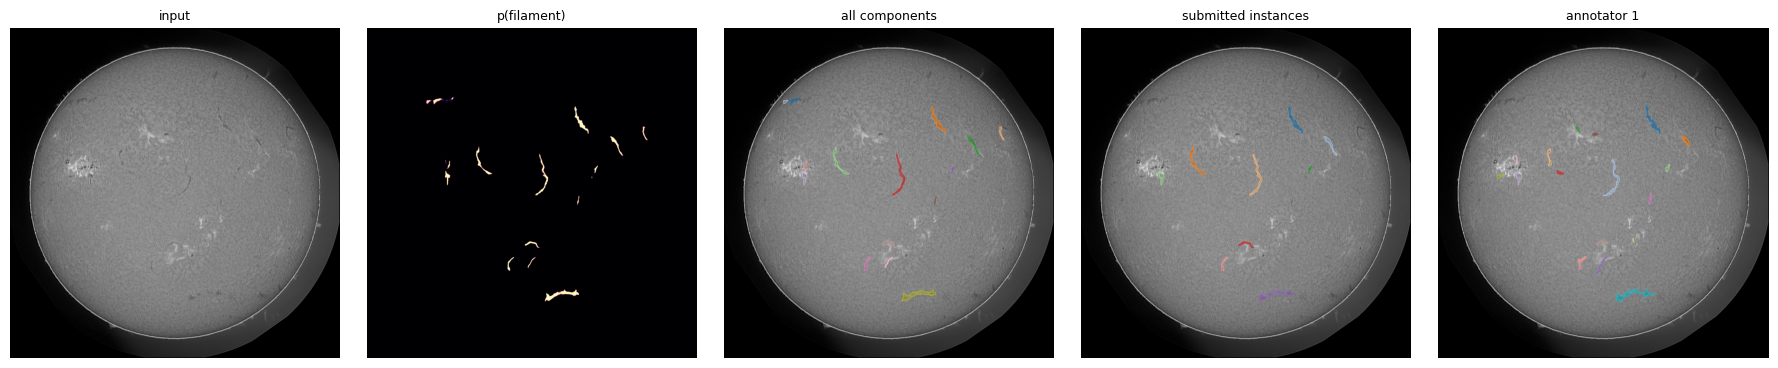

In [5]:
seg = FilamentSegmenter(WEIGHTS)
stem = "20130111104734Ch"  # a validation observation where the confidence cut matters
img = cv2.imread(str(DATA / "train/train_images" / f"{stem}.jpeg"))
prob = seg.probabilities(img)

post = PostProcess()
fg = (prob >= post.thresh * 255).astype(np.uint8)
closed = cv2.morphologyEx(fg, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9)))
loose = instances(prob, PostProcess(min_score=0.0))
kept = instances(prob, post)
print(f"{len(loose)} components >= {post.min_area} px, {len(kept)} kept with mean p >= {post.min_score}")

viz.show_row([
    ("input", cv2.cvtColor(img, cv2.COLOR_BGR2RGB)),
    ("p(filament)", prob),
    ("all components", viz.overlay(img, [r for _, r in loose])),
    ("submitted instances", viz.overlay(img, [r for _, r in kept])),
    ("annotator 1", viz.overlay(img, gt_val[stem][0])),
], size=3.6, cmap="magma");

## 5. Validation metrics (competition rubric)

Each prediction set is scored against every annotator view of its observation and the counts are pooled, as in the organisers' self-evaluation notebook. The reference row scores each annotator against the other annotators of the same observation, i.e. how well humans agree with each other.

In [6]:
t = time.perf_counter()
preds_val = {s: seg(cv2.imread(str(DATA / "train/train_images" / f"{s}.jpeg"))) for s in gt_val}
print(f"{len(preds_val)} images in {time.perf_counter() - t:.1f} s")
rep, ann = evaluate(gt_val, preds_val), inter_annotator(gt_val)

import pandas as pd
pd.DataFrame({"model": rep.summary(), "annotators vs each other": ann.summary()}).round(3)

144 images in 10.9 s


,model,annotators vs each other
PQ,0.429,0.334
SQ,0.675,0.631
RQ,0.635,0.529
TP,1138.000,1068.000
FP,589.000,949.000
FN,719.000,949.000
mean image Dice,0.668,0.633
mean matched Dice,0.803,0.771
one-to-many (% of GT),4.146,3.371
many-to-one (% of pred),3.358,3.371


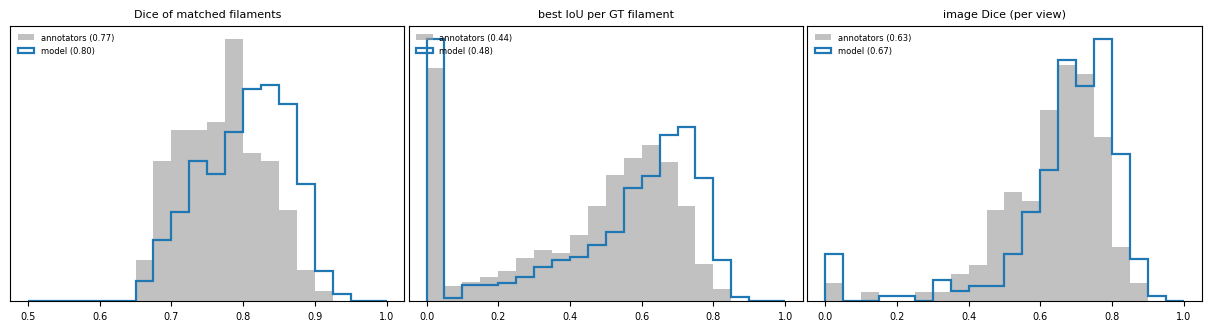

In [7]:
viz.distributions(rep, ann, figsize=(12, 3.2));

## 6. Test predictions -> submission

The same pipeline on the 180 test images. The resulting CSV is compared with the file submitted to Kaggle (`submissions/sem_s2048_prob_conf.csv`, public leaderboard 0.38).

In [8]:
test_paths = sorted((DATA / "test/test_images").glob("*.jpeg"))
preds_test = {p.stem: seg(cv2.imread(str(p))) for p in test_paths}
write_submission(preds_test, "submission.csv")
same = (ROOT / "submission.csv").read_bytes() == (ROOT / "submissions/sem_s2048_prob_conf.csv").read_bytes()
print("identical to the submitted file:", same)

1189 filaments over 180 images -> submission.csv
identical to the submitted file: True


## 7. End-to-end latency

JPEG path -> list of non-overlapping RLEs, batch 1, PyTorch (no TensorRT), averaged over validation images after warm-up.

In [9]:
stems = sorted(gt_val)[:43]
times = {"decode": [], "network": [], "post-processing": [], "total": []}
for i, s in enumerate(stems):
    torch.cuda.synchronize(); t0 = time.perf_counter()
    im = cv2.imread(str(DATA / "train/train_images" / f"{s}.jpeg")); t1 = time.perf_counter()
    p = seg.probabilities(im); torch.cuda.synchronize(); t2 = time.perf_counter()
    instances(p); t3 = time.perf_counter()
    if i >= 3:
        for k, v in zip(times, (t1 - t0, t2 - t1, t3 - t2, t3 - t0)):
            times[k].append(1000 * v)
print(torch.cuda.get_device_name())
print({k: f"{np.mean(v):.1f} ms" for k, v in times.items()})
print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

NVIDIA GeForce RTX 5070 Ti
{'decode': '10.6 ms', 'network': '56.7 ms', 'post-processing': '8.5 ms', 'total': '75.8 ms'}
peak GPU memory: 1.5 GB
